# 06 Model comparison and model choice (optional, added after the first test evaluation)

- What it does: compares four more algorithms, and LightGBM without location, with the baselines and M1 on the same task, then saves the numbers the choice of final model rests on.
- Inputs: `data/processed/model_table.parquet`; the saved predictions of B0, B1, B2, M1, M2 and M3 in `preds/`; `docs/FROZEN_CONFIG.json`; `docs/FROZEN_CONFIG_COMPARISON.json` for the test part; `results/results.csv`, `results/impact.csv`, `results/rule_sensitivity.csv`, `results/finetune_test.csv` and `results/location_sensitivity_val.csv`, which it checks its own numbers against.
- Outputs: `results/comparison_grid_val.csv`, `results/comparison_val.csv`, `results/comparison_selected_settings.json`, `results/comparison_test.csv`, `results/comparison_differences.csv`, `results/comparison_tradeoffs.csv`, `results/comparison_capacity_differences.csv`, `results/comparison_lasso_weights.csv`, `results/readme_table.csv`, `results/figures/model_comparison.png`, and the predictions `preds/C*_val.csv`, `preds/C*_test.csv`, `preds/M1_lgbm_no_location_val.csv`, `preds/M1_lgbm_no_location_test.csv`.

The task, the 17 inputs, the time splits and the metrics are those of notebooks 02 to 04. The added models:

- C1 ridge logistic regression (L2 penalty) and C2 LASSO logistic regression (L1 penalty). Ridge and LASSO regression would return numbers that are not probabilities on a 0/1 label, so we use logistic regression with the same penalties. B2 is already the ridge version at `C = 1`, so C1 measures what tuning the penalty adds.
- C3 random forest and C4 XGBoost.
- LightGBM without zip code and neighborhood, with M1's frozen settings. The project recommends this version, and notebook 03 checked it on 2023 only.

The protocol is the one the repo already uses. Settings are chosen on the validation year (2023) and written to a frozen file. Only then are the models refitted on 2016 to 2023 and scored once on the test years. All of these models were added after the first test scoring, so their test rows carry the same caveat as M3.

Nothing written by notebooks 01 to 05 is overwritten. Run time: about 12 minutes on an M-series laptop.

In [1]:
import sys
sys.path.insert(0, "..")

import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore")
warnings.filterwarnings("error", category=ConvergenceWarning)      # a logistic regression that did not converge must stop the run

from src import compare as C
from src import evaluate as E
from src import impact as I
from src import models as M

pd.set_option("display.width", 230)
pd.set_option("display.max_colwidth", 80)

BASELINES = ["B0_random", "B1_past_fail_rate", "B2_logreg", "M1_lgbm"]   # already scored in notebooks 02 to 04
NEW = list(C.GRIDS)                                                      # C1 to C4: settings chosen below
NO_LOC = C.NO_LOCATION                                                   # M1's settings, without zip code and neighborhood
TEXT = ["M2_lgbm_text", "M3_lgbm_finetuned"]                             # scored in notebooks 04 and 05
LABELS = {**E.MODEL_LABELS, **C.LABELS}

FROZEN_M1 = json.load(open("../docs/FROZEN_CONFIG.json"))
assert FROZEN_M1["history_features"] == M.HISTORY_FEATURES, "feature list changed after the freeze"
lgbm_keys = ["num_leaves", "learning_rate", "n_estimators"]
m1_params = {k: FROZEN_M1["M1_lgbm"][k] for k in lgbm_keys}


def saved(name, rows, split):
    """Saved predictions of an existing model, checked to be in the same row order as `rows`."""
    preds = pd.read_csv(f"../preds/{name}_{split}.csv", dtype={"inspection_id": str})
    assert (preds["inspection_id"].to_numpy() == rows["inspection_id"].to_numpy()).all(), f"{name}: rows differ"
    return preds["score"].to_numpy()

In [2]:
table = M.load_model_table("../data/processed/model_table.parquet")
train, val = table[table["split"] == "train"], table[table["split"] == "val"]
y_val, val_groups = val[M.TARGET].to_numpy(), val["licenseno"].to_numpy()
print(f"train {len(train):,} rows (2016 to 2022) | validation {len(val):,} rows (2023) | "
      f"{M.linear_matrix(train).shape[1]} columns after one-hot encoding")

# Two checks that this notebook sees the same data, prepared the same way, as notebooks 02 and 03.
ridge_at_1 = C.score(C.fit("C1_ridge_logreg", train, {"C": 1}), val)
assert np.allclose(ridge_at_1, saved("B2_logreg", val, "val")), "ridge at C=1 should be B2"
m1 = M.fit_lgbm(train, M.HISTORY_FEATURES, m1_params)
assert np.allclose(m1.predict_proba(val[M.HISTORY_FEATURES])[:, 1], saved("M1_lgbm", val, "val")), "M1 does not reproduce"
print("checks passed: ridge at C=1 reproduces B2, and M1 refitted from the frozen settings reproduces its saved predictions")

train 35,872 rows (2016 to 2022) | validation 5,521 rows (2023) | 68 columns after one-hot encoding


checks passed: ridge at C=1 reproduces B2, and M1 refitted from the frozen settings reproduces its saved predictions


## 1. Settings chosen on the validation year (2023)

Each added algorithm gets a small grid. For every setting the model is fitted on 2016 to 2022 and scored on 2023. We keep the setting with the best hit rate in the first 20% of visits. Ties go to the higher AUC, then to the simpler setting. LightGBM was tuned the same way, over 12 settings (notebook 03).

`C` is the inverse of the penalty strength: a small `C` is a strong penalty. For XGBoost, `n_estimators` is an upper limit, and early stopping on the validation AUC decides how many trees are used, as for LightGBM.

LightGBM without location has nothing to choose: it takes M1's frozen settings.

In [3]:
grids, selected = [], {}
for name in NEW:
    grid, best = C.grid_search(name, train, val)
    grids.append(grid)
    selected[name] = {"params": best, "fixed": C.FIXED[name], "settings_tried": len(grid)}
    print(f"{LABELS[name]}: {len(grid)} settings tried, validation hit rate from "
          f"{grid['precision_at_k'].min():.1%} to {grid['precision_at_k'].max():.1%} | selected {best}")
grid_table = pd.concat(grids, ignore_index=True)
grid_table.to_csv("../results/comparison_grid_val.csv", index=False)

settings = {
    "status": "added after the first test evaluation; settings chosen on validation (2023) only; the final model is not re-picked from this comparison",
    "seed": M.SEED,
    "selection_metric": "precision_at_k on validation (2023); ties go to the higher AUC, then to the simpler setting",
    "features": "the 17 history features of docs/FROZEN_CONFIG.json, as the one-hot matrix of models.linear_matrix",
    "fit_rows_for_test": "train + validation (2016 to 2023), as for every other model",
    **selected,
}
with open("../results/comparison_selected_settings.json", "w") as f:
    json.dump(settings, f, indent=2)
grid_table.round(4)

Ridge logistic regression: 6 settings tried, validation hit rate from 88.7% to 88.9% | selected {'C': 0.001}


LASSO logistic regression: 6 settings tried, validation hit rate from 88.9% to 89.3% | selected {'C': 0.001}


Random forest: 12 settings tried, validation hit rate from 89.6% to 90.5% | selected {'n_estimators': 500, 'max_depth': None, 'max_features': 'sqrt'}


XGBoost: 12 settings tried, validation hit rate from 88.6% to 90.9% | selected {'max_depth': 4, 'learning_rate': 0.05, 'n_estimators': 139}


,model,C,auc,catch_at_k,precision_at_k,n,n_estimators,max_depth,max_features,learning_rate,best_iteration
0,C1_ridge_logreg,0.001,0.7784,0.3189,0.8895,5521,NaN,NaN,NaN,NaN,NaN
1,C1_ridge_logreg,0.010,0.7775,0.3180,0.8868,5521,NaN,NaN,NaN,NaN,NaN
2,C1_ridge_logreg,0.100,0.7763,0.3189,0.8895,5521,NaN,NaN,NaN,NaN,NaN
3,C1_ridge_logreg,1.000,0.7761,0.3189,0.8895,5521,NaN,NaN,NaN,NaN,NaN
4,C1_ridge_logreg,10.000,0.7761,0.3189,0.8895,5521,NaN,NaN,NaN,NaN,NaN
5,C1_ridge_logreg,100.000,0.7761,0.3189,0.8895,5521,NaN,NaN,NaN,NaN,NaN
6,C2_lasso_logreg,0.001,0.7638,0.3202,0.8931,5521,NaN,NaN,NaN,NaN,NaN
7,C2_lasso_logreg,0.010,0.7784,0.3189,0.8895,5521,NaN,NaN,NaN,NaN,NaN
8,C2_lasso_logreg,0.100,0.7768,0.3189,0.8895,5521,NaN,NaN,NaN,NaN,NaN
9,C2_lasso_logreg,1.000,0.7763,0.3189,0.8895,5521,NaN,NaN,NaN,NaN,NaN


In [4]:
# Refit each model at its selected setting, save its validation predictions, and compare with the baselines.
val_scores = {name: saved(name, val, "val") for name in BASELINES}
for name in NEW:
    model = C.fit(name, train, selected[name]["params"])
    val_scores[name] = C.score(model, val)
    M.save_preds(val, val_scores[name], f"../preds/{name}_val.csv")
    best_in_grid = grid_table[grid_table["model"] == name]["precision_at_k"].max()
    assert np.isclose(E.evaluate(y_val, val_scores[name])["precision_at_k"], best_in_grid), f"{name}: refit differs from the grid"
    if name == "C2_lasso_logreg":
        weights = model[-1].coef_.ravel()
        print(f"LASSO keeps {int((weights != 0).sum())} of {weights.size} weights at the selected C (fit on 2016 to 2022). "
              f"The {weights.size} are the {M.linear_matrix(train).shape[1]} columns plus one missing-value flag per input that has gaps.")

# LightGBM without location: same settings as M1. Notebook 03 reported its 2023 hit rate; we must find the same number.
val_scores[NO_LOC] = C.score_no_location(C.fit_no_location(train, m1_params), val)
M.save_preds(val, val_scores[NO_LOC], f"../preds/{NO_LOC}_val.csv")
reported = pd.read_csv("../results/location_sensitivity_val.csv")["precision_at_k"][0]
assert np.isclose(E.evaluate(y_val, val_scores[NO_LOC])["precision_at_k"], reported), "no-location model differs from notebook 03"

val_results = E.results_table(y_val, val_scores, groups=val_groups)
val_results.to_csv("../results/comparison_val.csv", index=False)
val_diffs = pd.concat([E.difference_table(y_val, val_scores, name, ["M1_lgbm", "B2_logreg"], groups=val_groups)
                       for name in NEW + [NO_LOC]], ignore_index=True)
val_diffs.insert(0, "split", "val")
print(val_results[["model", "precision_at_k", "precision_at_k_lo", "precision_at_k_hi", "catch_at_k", "auc"]].round(3).to_string(index=False))
print()
print(val_diffs[val_diffs["metric"] == "precision_at_k"].drop(columns=["split", "metric"]).round(4).to_string(index=False))

LASSO keeps 17 of 77 weights at the selected C (fit on 2016 to 2022). The 77 are the 68 columns plus one missing-value flag per input that has gaps.


              model  precision_at_k  precision_at_k_lo  precision_at_k_hi  catch_at_k   auc
          B0_random           0.558              0.543              0.572       0.200 0.500
  B1_past_fail_rate           0.804              0.777              0.829       0.288 0.717
          B2_logreg           0.889              0.867              0.910       0.319 0.776
            M1_lgbm           0.905              0.884              0.924       0.324 0.780
    C1_ridge_logreg           0.889              0.870              0.910       0.319 0.778
    C2_lasso_logreg           0.893              0.873              0.915       0.320 0.764
   C3_random_forest           0.905              0.885              0.924       0.324 0.780
         C4_xgboost           0.909              0.886              0.928       0.326 0.785
M1_lgbm_no_location           0.900              0.880              0.921       0.323 0.776

              model     minus  difference   ci_lo   ci_hi      verdict
    C1_r

## 2. Test years (runs only after the settings are frozen)

The cells below run only once the selected settings have been copied to `docs/FROZEN_CONFIG_COMPARISON.json` and committed. They check that the frozen file still equals what the grid search selects, refit every added model on 2016 to 2023 and score the test years (2024 to November 2026) once. With data that differs from our snapshot, early stopping can select a different number of trees. The notebook then stops, by design, instead of scoring a model that was not frozen.

The rows for B0, B1, B2 and M1 come from their saved test predictions and must equal `results/results.csv`.

In [5]:
FROZEN_PATH = Path("../docs/FROZEN_CONFIG_COMPARISON.json")
FROZEN = json.load(open(FROZEN_PATH)) if FROZEN_PATH.exists() else None
if FROZEN is None:
    print("Not frozen yet. Copy results/comparison_selected_settings.json to docs/FROZEN_CONFIG_COMPARISON.json, "
          "commit it, and rerun this notebook to score the test years.")
else:
    assert FROZEN == json.load(open("../results/comparison_selected_settings.json")), "settings changed after the freeze"
    fit_rows, test = table[table["split"].isin(["train", "val"])], table[table["split"] == "test"]
    assert fit_rows["date"].max() < pd.Timestamp("2024-01-01") <= test["date"].min()      # nothing is fitted on the test period
    y_test, test_groups = test[M.TARGET].to_numpy(), test["licenseno"].to_numpy()

    test_scores = {name: saved(name, test, "test") for name in BASELINES}
    for name in NEW:
        model = C.fit(name, fit_rows, FROZEN[name]["params"])
        test_scores[name] = C.score(model, test)
        M.save_preds(test, test_scores[name], f"../preds/{name}_test.csv")
        if name == "C2_lasso_logreg":
            lasso = model
            weights = model[-1].coef_.ravel()
            print(f"LASSO keeps {int((weights != 0).sum())} of {weights.size} weights when refitted on 2016 to 2023")
    test_scores[NO_LOC] = C.score_no_location(C.fit_no_location(fit_rows, m1_params), test)
    M.save_preds(test, test_scores[NO_LOC], f"../preds/{NO_LOC}_test.csv")

    test_results = E.results_table(y_test, test_scores, groups=test_groups)
    published = pd.read_csv("../results/results.csv").set_index("model")
    for name in BASELINES:
        ours = test_results.set_index("model").loc[name]
        assert np.allclose(ours[["auc", "catch_at_k", "precision_at_k"]].astype(float),
                           published.loc[name, ["auc", "catch_at_k", "precision_at_k"]].astype(float)), name
    print(f"fit on {len(fit_rows):,} inspections (2016 to 2023) | test on {len(test):,} | "
          "the four existing rows equal results/results.csv")

LASSO keeps 19 of 77 weights when refitted on 2016 to 2023


fit on 41,393 inspections (2016 to 2023) | test on 17,171 | the four existing rows equal results/results.csv


In [6]:
if FROZEN is not None:
    test_diffs = pd.concat([E.difference_table(y_test, test_scores, name, ["M1_lgbm", "B2_logreg"], groups=test_groups)
                            for name in NEW + [NO_LOC]], ignore_index=True)
    test_diffs.insert(0, "split", "test")
    pd.concat([val_diffs, test_diffs], ignore_index=True).to_csv("../results/comparison_differences.csv", index=False)

    def settings_text(name):
        if name in NEW:
            return ", ".join(f"{k}={'no limit' if v is None else v}" for k, v in FROZEN[name]["params"].items())
        if name == "M1_lgbm":
            return ", ".join(f"{k}={m1_params[k]}" for k in lgbm_keys)
        return {"B0_random": "none", "B1_past_fail_rate": "none (a rule)", "B2_logreg": "C=1 (default, not tuned)",
                NO_LOC: "M1's settings, without zip code and neighborhood"}[name]

    vs_m1 = test_diffs[(test_diffs["minus"] == "M1_lgbm") & (test_diffs["metric"] == "precision_at_k")].set_index("model")
    m1_settings_tried = int(np.prod([len(v) for v in M.LGBM_GRID.values()]))
    test_results.insert(1, "settings", [settings_text(m) for m in test_results["model"]])
    test_results.insert(2, "settings_tried", [FROZEN[m]["settings_tried"] if m in NEW else {"M1_lgbm": m1_settings_tried}.get(m, 0)
                                              for m in test_results["model"]])
    test_results["val_precision_at_k"] = test_results["model"].map(val_results.set_index("model")["precision_at_k"])
    for col, source in [("minus_M1", "difference"), ("minus_M1_lo", "ci_lo"), ("minus_M1_hi", "ci_hi"), ("minus_M1_verdict", "verdict")]:
        test_results[col] = test_results["model"].map(vs_m1[source])
    # Why earlier matters: the share of all serious (level 3) violations that the first 20% of visits find.
    # n_lvl3 is what each test inspection FOUND. It is an outcome, used here only to measure results.
    serious = test["n_lvl3"].to_numpy()
    test_results["serious_share_at_k"] = [I.severity_in_first_visits(serious, test_scores[m])[0] for m in test_results["model"]]
    published_impact = pd.read_csv("../results/impact.csv").set_index("quantity")["value"]
    impact_names = {"B0_random": "random order", "B1_past_fail_rate": "past-failure-rate rule (B1)",
                    "B2_logreg": "B2_logreg", "M1_lgbm": "M1_lgbm"}
    for name, label in impact_names.items():
        ours = test_results.set_index("model").loc[name, "serious_share_at_k"]
        theirs = published_impact[f"Share of all serious (level 3) violations found in the first 20% of visits, {label}"]
        assert np.isclose(ours, theirs), f"{name}: serious-violation share differs from results/impact.csv"
    test_results.to_csv("../results/comparison_test.csv", index=False)

    show = pd.DataFrame({
        "model": [LABELS[m] for m in test_results["model"]],
        "settings": test_results["settings"],
        "2023 hit rate": (test_results["val_precision_at_k"] * 100).round(1),
        "test hit rate": (test_results["precision_at_k"] * 100).round(1),
        "95% range": [f"{lo * 100:.1f} to {hi * 100:.1f}" for lo, hi in zip(test_results["precision_at_k_lo"], test_results["precision_at_k_hi"])],
        "test catch": (test_results["catch_at_k"] * 100).round(1),
        "test AUC": test_results["auc"].round(3),
        "serious found": (test_results["serious_share_at_k"] * 100).round(1),
        "vs. LightGBM (points)": ["" if pd.isna(d) else f"{d * 100:+.1f} ({lo * 100:+.1f} to {hi * 100:+.1f}), {v}"
                                  for d, lo, hi, v in zip(test_results["minus_M1"], test_results["minus_M1_lo"],
                                                          test_results["minus_M1_hi"], test_results["minus_M1_verdict"])],
    })
    print(show.to_string(index=False))

                          model                                                settings  2023 hit rate  test hit rate    95% range  test catch  test AUC  serious found             vs. LightGBM (points)
   No ranking (reference point)                                                    none           55.8           59.0 57.8 to 59.9        20.0     0.500           20.0                                  
Past failure rate (simple rule)                                           none (a rule)           80.4           80.3 78.5 to 81.7        27.2     0.698           33.2                                  
            Logistic regression                                C=1 (default, not tuned)           88.9           87.0 85.2 to 88.2        29.5     0.736           38.8                                  
              LightGBM, history     num_leaves=31, learning_rate=0.02, n_estimators=231           90.5           88.1 86.4 to 89.4        29.9     0.748           40.0                         

Hit rate: the share of the first 20% of visits that find a failure. Catch: the share of all failures those visits find. Serious found: the share of all serious (level 3) violations those visits find. The 95% ranges resample whole restaurants. The last column is the paired difference from LightGBM (M1) on the test years, with the verdict wording fixed in `src/evaluate.py` before the first test scoring.

## 3. What the choice of final model rests on

At 20% of visits the learned models are close, so the choice has to look further: at tighter capacities, at how early failures are found over a whole quarter, at whether a risk of 90% means 90%, and at where the first visits land. The two text models (M2 and M3) are included from their saved predictions.

- `precision_at_5pct`, `precision_at_10pct`, `precision_at_20pct`: hit rate when only the first 5%, 10% or 20% of visits are counted.
- `weeks_earlier`: how much sooner a visit that ends in a failure happens when each quarter's visits are made in risk order (the method of notebook 04).
- `calibration_gap`: the average distance between predicted risk and observed fail rate over ten equal groups. `top_tenth_predicted` and `top_tenth_observed` give the riskiest group.
- `dorchester_in_first_visits`, `roxbury_in_first_visits`: the share of each neighborhood's inspections that land in the first 20% of visits. The two fail equally often (66%). `neighborhood_spread` is the largest share minus the smallest across neighborhoods with at least 200 test inspections.

In [7]:
if FROZEN is not None:
    candidates = {m: s for m, s in test_scores.items() if m not in ("B0_random", "B1_past_fail_rate")}
    for name in TEXT:
        if Path(f"../preds/{name}_test.csv").exists():
            candidates[name] = saved(name, test, "test")

    rows = []
    for name, score in candidates.items():
        calib = I.calibration_table(y_test, score)
        hoods = I.neighborhood_table(test["neighborhood"], y_test, score).set_index("neighborhood")["share_in_first_visits"]
        rows.append({
            "model": name,
            **{f"precision_at_{int(k * 100)}pct": E.evaluate(y_test, score, k)["precision_at_k"] for k in (0.05, 0.10, 0.20)},
            "auc": E.evaluate(y_test, score)["auc"],
            "weeks_earlier": I.weeks_earlier(test["date"], y_test, score)["mean_weeks_earlier_failures"],
            "calibration_gap": (calib["n"] * (calib["mean_predicted_risk"] - calib["observed_fail_rate"]).abs()).sum() / calib["n"].sum(),
            "top_tenth_predicted": calib["mean_predicted_risk"].iloc[-1], "top_tenth_observed": calib["observed_fail_rate"].iloc[-1],
            "dorchester_in_first_visits": hoods["Dorchester"], "roxbury_in_first_visits": hoods["Roxbury"],
            "neighborhood_spread": hoods.max() - hoods.min(),
        })
    tradeoffs = pd.DataFrame(rows)
    tradeoffs.to_csv("../results/comparison_tradeoffs.csv", index=False)
    print(tradeoffs.assign(model=[LABELS[m] for m in tradeoffs["model"]]).round(3).to_string(index=False))

    # Paired differences from M1 at tighter capacities (2,000 resamples of restaurants, as for the robustness slices).
    capacity_rows = []
    for k in (0.05, 0.10):
        for name in [m for m in candidates if m != "M1_lgbm"]:
            d, lo, hi = E.paired_differences(y_test, candidates[name], candidates["M1_lgbm"], n=2000, k=k, groups=test_groups)["precision_at_k"]
            capacity_rows.append({"capacity": k, "model": name, "minus": "M1_lgbm", "difference": d, "ci_lo": lo, "ci_hi": hi,
                                  "verdict": E.verdict(d, lo, hi)})
    capacity_diffs = pd.DataFrame(capacity_rows)
    capacity_diffs.to_csv("../results/comparison_capacity_differences.csv", index=False)
    print()
    print(capacity_diffs.assign(model=[LABELS[m] for m in capacity_diffs["model"]]).round(4).to_string(index=False))

                              model  precision_at_5pct  precision_at_10pct  precision_at_20pct   auc  weeks_earlier  calibration_gap  top_tenth_predicted  top_tenth_observed  dorchester_in_first_visits  roxbury_in_first_visits  neighborhood_spread
                Logistic regression              0.921               0.906               0.870 0.736          1.054            0.034                0.923               0.906                       0.485                    0.207                0.490
                  LightGBM, history              0.937               0.927               0.881 0.748          1.114            0.032                0.934               0.927                       0.458                    0.194                0.474
          Ridge logistic regression              0.917               0.906               0.869 0.736          1.052            0.021                0.900               0.906                       0.504                    0.205                0.510
        


 capacity                               model   minus  difference   ci_lo   ci_hi      verdict
     0.05                 Logistic regression M1_lgbm     -0.0163 -0.0317  0.0035   borderline
     0.05           Ridge logistic regression M1_lgbm     -0.0198 -0.0353 -0.0023   borderline
     0.05           LASSO logistic regression M1_lgbm     -0.0186 -0.0373 -0.0012   borderline
     0.05                       Random forest M1_lgbm     -0.0035 -0.0187  0.0105 within noise
     0.05                             XGBoost M1_lgbm      0.0035 -0.0058  0.0117 within noise
     0.05           LightGBM without location M1_lgbm      0.0058 -0.0058  0.0197 within noise
     0.05            LightGBM, history + text M1_lgbm     -0.0023 -0.0139  0.0092 within noise
     0.05 LightGBM, history + fine-tuned text M1_lgbm      0.0035 -0.0082  0.0187 within noise
     0.10                 Logistic regression M1_lgbm     -0.0215 -0.0339 -0.0122 beyond noise
     0.10           Ridge logistic regression M1_

In [8]:
if FROZEN is not None:
    # What the LASSO model relies on. Inputs are scaled before fitting, so the sizes of the weights can be compared.
    columns = list(M.linear_matrix(fit_rows).columns)
    columns += [f"missing: {columns[i]}" for i in lasso[0].indicator_.features_]
    weights = pd.Series(lasso[-1].coef_.ravel(), index=columns)
    kept = weights[weights != 0].sort_values(key=abs, ascending=False).rename_axis("input").reset_index(name="weight")
    kept.to_csv("../results/comparison_lasso_weights.csv", index=False)
    is_location = kept["input"].str.startswith(("zip_", "neighborhood_"))
    n_location = sum(c.startswith(("zip_", "neighborhood_")) for c in columns)
    print(f"LASSO keeps {len(kept)} of {len(weights)} weights. Location columns kept: {int(is_location.sum())} of {n_location}.")
    print(kept.round(3).to_string(index=False))

LASSO keeps 19 of 77 weights. Location columns kept: 3 of 53.
                           input  weight
             last_routine_n_viol   0.434
         prior_routine_fail_rate   0.409
                       last_fail  -0.167
                      prior_n_3y   0.119
                       zip_02110  -0.015
               last_routine_fail   0.015
         neighborhood_Dorchester   0.015
             neighborhood_Boston  -0.015
                           month  -0.012
                        is_first  -0.006
        missing: prior_fail_rate  -0.006
missing: prior_routine_fail_rate  -0.006
              missing: last_fail  -0.006
            missing: last_n_viol  -0.006
            missing: last_n_lvl3  -0.006
      missing: last_routine_fail  -0.006
    missing: last_routine_n_viol  -0.006
    missing: last_routine_n_lvl3  -0.006
        missing: days_since_last  -0.006


### One table and one chart for the README

`results/readme_table.csv` holds every row of the README's results table, computed here from the saved predictions with the same code. The rows that other notebooks already report (the second simple rule, M2 and M3) must equal those files. † marks what was added after the first test scoring.

                                               label  precision_at_k  precision_at_k_lo  precision_at_k_hi  catch_at_k   auc  serious_share_at_k
                        No ranking (reference point)            59.0               57.8               59.9        20.0 0.500                20.0
                     Past failure rate (simple rule)            80.3               78.5               81.7        27.2 0.698                33.2
Rule: most violations at the last routine inspection            81.9               80.4               83.4        27.8 0.683                39.0
                                 Logistic regression            87.0               85.2               88.2        29.5 0.736                38.8
                                   LightGBM, history            88.1               86.4               89.4        29.9 0.748                40.0
                         LightGBM without location †            88.7               87.1               89.9        30.1 0.746      

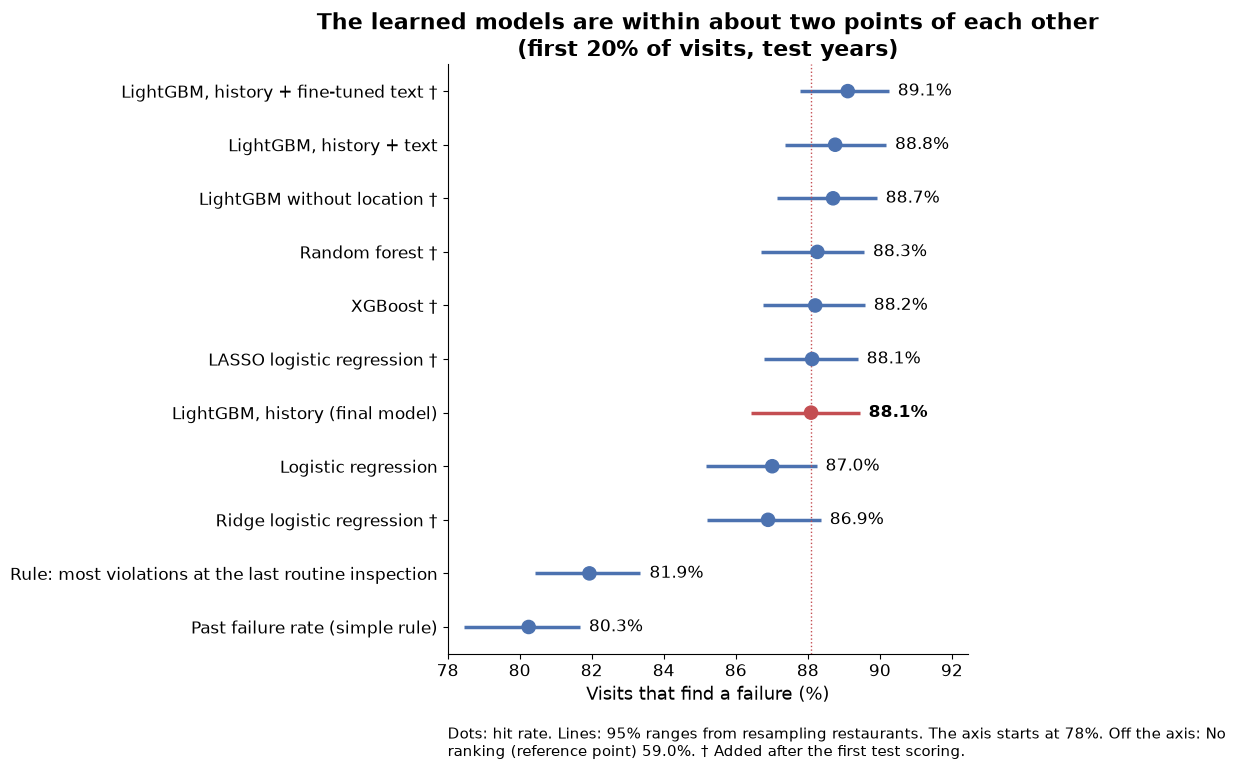

In [9]:
if FROZEN is not None:
    extra = {"S1_last_routine_violations": M.score_simple_rule(test), **{m: candidates[m] for m in TEXT if m in candidates}}
    extra_results = E.results_table(y_test, extra, groups=test_groups)
    extra_results["serious_share_at_k"] = [I.severity_in_first_visits(serious, extra[m])[0] for m in extra_results["model"]]
    shared = ["model", "precision_at_k", "precision_at_k_lo", "precision_at_k_hi", "catch_at_k", "auc", "serious_share_at_k"]
    readme = pd.concat([test_results[shared], extra_results[shared]], ignore_index=True).set_index("model")
    order = ["B0_random", "B1_past_fail_rate", "S1_last_routine_violations", "B2_logreg", "M1_lgbm", NO_LOC] + NEW + [m for m in TEXT if m in extra]
    readme = readme.loc[order].reset_index()
    planned = BASELINES + ["M2_lgbm_text", "S1_last_routine_violations"]   # fixed in docs/FROZEN_CONFIG.json before any test scoring
    readme.insert(1, "label", [LABELS[m] + ("" if m in planned else " †") for m in readme["model"]])

    checks = {"S1_last_routine_violations": "../results/rule_sensitivity.csv", "M2_lgbm_text": "../results/results.csv",
              "M3_lgbm_finetuned": "../results/finetune_test.csv"}
    for name, path in checks.items():
        if name in set(readme["model"]):
            theirs = pd.read_csv(path).set_index("model").loc[name]
            ours = readme.set_index("model").loc[name]
            cols = ["precision_at_k", "precision_at_k_lo", "precision_at_k_hi", "auc"]
            assert np.allclose(ours[cols].astype(float), theirs[cols].astype(float)), f"{name} differs from {path}"
    readme.to_csv("../results/readme_table.csv", index=False)
    percent = ["precision_at_k", "precision_at_k_lo", "precision_at_k_hi", "catch_at_k", "serious_share_at_k"]
    print(readme.assign(**{c: (readme[c] * 100).round(1) for c in percent}).round(3).drop(columns="model").to_string(index=False))

    fig = C.plot_comparison(readme, path="../results/figures/model_comparison.png")
    plt.show()

### Reading the comparison

- No algorithm beats M1 on the same inputs. Random forest, XGBoost and LASSO are within noise of it at 20% (+0.2, +0.1 and +0.0 points), and tuned ridge is within noise of B2.
- The linear models fall behind at the top of the list. In the first 10% of visits LASSO, ridge and B2 are 2.0 to 2.2 points below M1, beyond noise. Their risk estimates are also less accurate where the list is used: LASSO gives the riskiest tenth 86% and 91% of it fails, against 93% and 93% for M1.
- LASSO is the most transparent model. It keeps 19 of 77 weights, and four of them carry the score: violations at the last routine inspection, the share of past routine inspections failed, whether the previous visit failed, and the number of inspections in the last three years. It keeps 3 of the 53 location columns.
- The text models are the most accurate at 20% (M3 leads M1 by 1.0 point, beyond noise). In the first 5% and 10% of visits they are within noise of M1, and M3 finds failures 0.01 weeks earlier.
- LightGBM without location is within noise of M1 on every measure and nominally ahead on the hit rate: 88.7% against 88.1% at 20% (+0.6 points, 95% range -0.3 to +1.3) and 93.1% against 92.7% at 10%. Under it, 35% of Dorchester's inspections and 24% of Roxbury's land in the first visits, against 46% and 19% under M1. Both neighborhoods fail 66% of the time.

The choice. M1 stays the final model. It was fixed on 2023 before the test years were scored, it is in the most accurate group at every capacity, and its estimates for the riskiest restaurants are accurate. For use, we recommend the same model without zip code and neighborhood: accuracy is unchanged within noise and the first visits follow the fail rate more closely. LASSO is the model to choose if a formula short enough to read matters more than two points in the first 10% of visits. M3 is the model to choose if one more point at 20% is worth a neural network that reads inspector comments.